<h3>Data modeling</h3>

<p>Importing the initail version of preprocessed data for data modeling</p>

In [1]:
import pandas as pd
df = pd.read_csv('Data/cleaned_fake_job_postings.csv')

In [2]:
df.head(5)

,job_id,title,location,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,marketing intern,"US, NY, New York",food weve created groundbreaking awardwinning ...,food fastgrowing james beard awardwinning onli...,experience content management systems major pl...,unknown,0,1,0,Other,Internship,Unknown,Unknown,Marketing,0
1,2,customer service cloud video production,"NZ, , Auckland",seconds worlds cloud video production service ...,organised focused vibrant awesomedo passion cu...,expect youyour key responsibility communicate ...,get usthrough part seconds team gainexperience...,0,1,0,Full-time,Not Applicable,Unknown,Marketing and Advertising,Customer Service,0
2,3,commissioning machinery assistant cma,"US, IA, Wever",valor services provides workforce solutions me...,client located houston actively seeking experi...,implement precommissioning commissioning proce...,unknown,0,1,0,Unknown,Unknown,Unknown,Unknown,Unknown,0
3,4,account executive washington dc,"US, DC, Washington",passion improving quality life geography heart...,company esri environmental systems research in...,education bachelors masters gis business admin...,culture anything corporatewe collaborative cre...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,bill review manager,"US, FL, Fort Worth",spotsource solutions llc global human capital ...,job title itemization review managerlocation f...,qualificationsrn license state texasdiploma ba...,full benefits offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


<h3>Lemmatization Process</h3>

In [3]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /Users/nani/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/nani/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /Users/nani/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [4]:
df['text_input'] = df['description'] + ' ' + df['requirements']

In [5]:
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

In [6]:
lemmatizer = WordNetLemmatizer()
def lemmatize_text(text):
    if isinstance(text, str):
        tokens = word_tokenize(text)
        pos_tags = pos_tag(tokens)
        lemmas = [lemmatizer.lemmatize(word, get_wordnet_pos(tag)) for word, tag in pos_tags]
        return ' '.join(lemmas)
    return text

In [7]:
df['lemmatized_text'] = df['text_input'].apply(lemmatize_text)

In [8]:
df['lemmatized_text'].head(10)

0    food fastgrowing james beard awardwinning onli...
1    organise focused vibrant awesomedo passion cus...
2    client locate houston actively seek experience...
3    company esri environmental system research ins...
4    job title itemization review managerlocation f...
5    job overviewapex environmental consulting firm...
6    responsibility manage englishspeaking editoria...
7    airenvyhey season entrepreneur heart san franc...
8    implementationconfigurationtestingtraining onh...
9    customer service associate base phoenix az rig...
Name: lemmatized_text, dtype: object

<h3>TF-IDF Vectorization</h3>

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [10]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

In [11]:
x_tfidf = tfidf_vectorizer.fit_transform(df['lemmatized_text'])
y = df['fraudulent']

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x_tfidf, y, test_size =0.2, random_state=42, stratify=y)

In [13]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

def plot_roc_curve(y_true, y_pred_probs, model_name="Model"):
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f"{model_name} (AUC = {roc_auc:.4f})")
    plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate (Recall)")
    plt.title(f"ROC Curve - {model_name}")
    plt.legend(loc="lower right")
    plt.grid()
    plt.show()


<h3>Implementing the data models</h3>

<h3>1. Logistic Regression</h3>

In [14]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score

In [15]:
log_reg_cv = LogisticRegression(max_iter=1000,class_weight='balanced')
cv_scores_log = cross_val_score(log_reg_cv, x_tfidf, y, cv=5, scoring='f1')
print(f"Logistic Regression 5-Fold CV F1 Score: {cv_scores_log.mean():.4f}")


Logistic Regression 5-Fold CV F1 Score: 0.5620


In [16]:
log_reg_cv.fit(X_train, y_train)

y_pred_log = log_reg_cv.predict(X_test)

log_reg_results = {
    "Accuracy": accuracy_score(y_test, y_pred_log),
    "Precision": precision_score(y_test, y_pred_log),
    "Recall": recall_score(y_test, y_pred_log),
    "F1 Score": f1_score(y_test, y_pred_log)
}

print("Logistic Regression Results:", log_reg_results)

Logistic Regression Results: {'Accuracy': 0.9510626398210291, 'Precision': 0.4967948717948718, 'Recall': 0.8959537572254336, 'F1 Score': 0.6391752577319587}


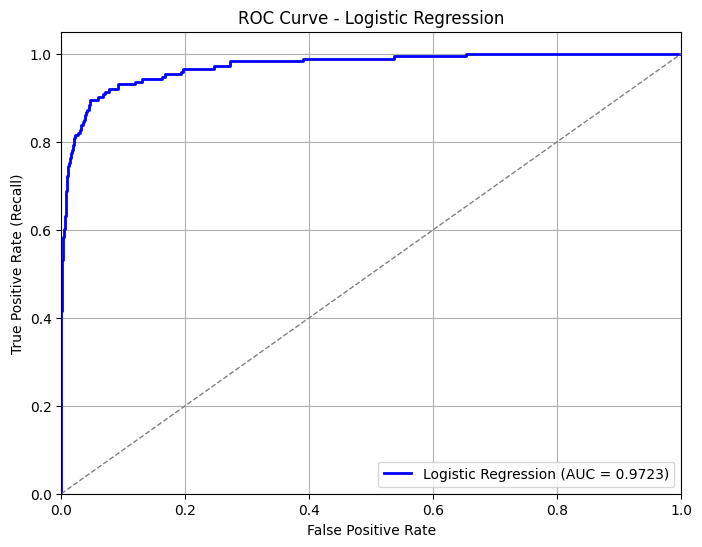

In [17]:
y_pred_proba_log = log_reg_cv.predict_proba(X_test)[:, 1]
plot_roc_curve(y_test, y_pred_proba_log, model_name="Logistic Regression")

In [18]:
from sklearn.metrics import roc_auc_score
roc_auc_log = roc_auc_score(y_test, y_pred_proba_log)
print(f"Logistic Regression ROC-AUC: {roc_auc_log:.4f}")

Logistic Regression ROC-AUC: 0.9723


<h3>2. XGB Classifier</h3>

In [19]:
from collections import Counter
counter = Counter(y_train)
scale_pos_weight = counter[0] / counter[1]
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

scale_pos_weight: 19.70


<p>To address the significant class imbalance in our dataset (where the majority of job postings are real and only a small portion are fraudulent), we used the `scale_pos_weight` parameter in XGBoost. This parameter adjusts the importance of the minority class (fraudulent = 1) during training, helping the model to better learn patterns associated with fraud.
</p>

In [20]:
xgb_cv = XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss')
cv_scores_xgb = cross_val_score(xgb_cv, x_tfidf, y, cv=5, scoring='f1')
print(f"XGBoost 5-Fold CV F1 Score: {cv_scores_xgb.mean():.4f}")

XGBoost 5-Fold CV F1 Score: 0.6691


In [21]:
xgb_cv.fit(X_train, y_train)
y_pred_xgb = xgb_cv.predict(X_test)
xgb_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1 Score": f1_score(y_test, y_pred_xgb)
}

print("XGBoost Results:", xgb_results)

XGBoost Results: {'Accuracy': 0.9781879194630873, 'Precision': 0.802547770700637, 'Recall': 0.7283236994219653, 'F1 Score': 0.7636363636363637}


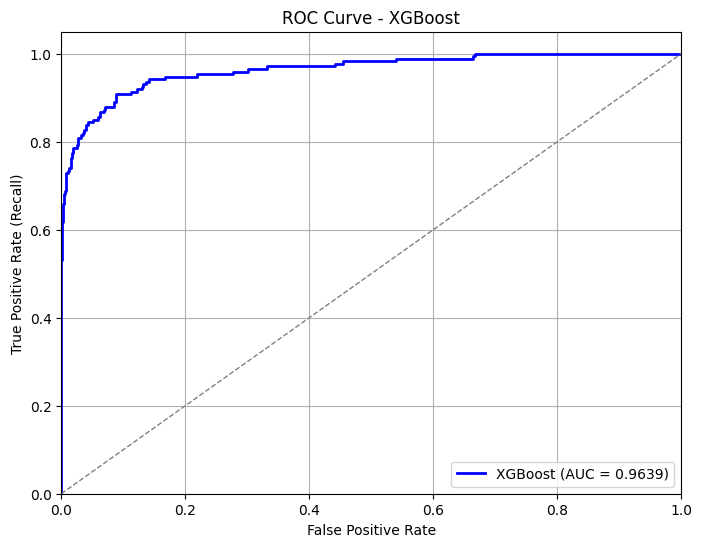

In [22]:
y_pred_proba_xgb = xgb_cv.predict_proba(X_test)[:, 1]
plot_roc_curve(y_test, y_pred_proba_xgb, model_name="XGBoost")

In [23]:
feature_names = tfidf_vectorizer.get_feature_names_out()
importances = xgb_cv.feature_importances_
top_indices = importances.argsort()[::-1][:20]

print("Top 20 Important Features (XGBoost):")
for idx in top_indices:
    print(f"{feature_names[idx]}: {importances[idx]:.4f}")


Top 20 Important Features (XGBoost):
oil: 0.0306
youll: 0.0175
web: 0.0165
two: 0.0160
love: 0.0126
robust: 0.0125
content: 0.0125
search: 0.0122
safety: 0.0120
website: 0.0120
join: 0.0110
creative: 0.0106
word: 0.0103
university: 0.0099
home: 0.0091
gas: 0.0090
beverage: 0.0090
specification: 0.0090
cash: 0.0089
detail: 0.0088


<h3>3. LSTM</h3>

In [24]:
import numpy as np
glove_path = 'Data/glove.6B/glove.6B.100d.txt'
embedding_index = {}
with open(glove_path, encoding="utf8") as f:
    for line in f:
        values = line.split()
        word = values[0]
        coef = np.asarray(values[1:], dtype='float32')
        embedding_index[word] = coef

In [25]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_NUM_WORDS = 10000
MAX_SEQUENCE_LENGTH = 100

# Recreate the tokenizer and fit on your lemmatized input
tokenizer = Tokenizer(num_words=MAX_NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df['lemmatized_text'])

# Generate sequences and pad them (if needed)
sequences = tokenizer.texts_to_sequences(df['lemmatized_text'])
X_padded = pad_sequences(sequences, maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')

# Target variable
y = df['fraudulent'].values


/Users/nani/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [26]:
EMBEDDING_DIM = 100

embedding_matrix = np.zeros((MAX_NUM_WORDS, EMBEDDING_DIM))
for word, i in tokenizer.word_index.items():
    if i < MAX_NUM_WORDS:
        embedding_vector = embedding_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector


In [27]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [28]:
model = Sequential([
    Embedding(
        input_dim=MAX_NUM_WORDS,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        input_length=MAX_SEQUENCE_LENGTH,
        trainable=False  # Keep GloVe embeddings fixed
    ),
    LSTM(128, return_sequences=False),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')  # Binary classification
])

/Users/nani/Library/Python/3.9/lib/python/site-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [29]:
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)


In [30]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,000,000 (3.81 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 1,000,000 (3.81 MB)

In [31]:
from sklearn.model_selection import train_test_split
X_train_lstm, X_test_lstm, y_train_lstm, y_test_lstm = train_test_split(
    X_padded, y, test_size=0.2, random_state=42, stratify=y
)

In [32]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Compute class weights
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_lstm), y=y_train_lstm)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights:", class_weight_dict)

# Fit LSTM model using class weights
history = model.fit(
    X_train_lstm, y_train_lstm,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    class_weight=class_weight_dict,  # 👈 Key addition
    verbose=1
)


Class weights: {0: np.float64(0.5253838806847403), 1: np.float64(10.34876989869754)}
Epoch 1/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - accuracy: 0.6971 - loss: 0.6868 - precision: 0.0658 - recall: 0.4159 - val_accuracy: 0.4121 - val_loss: 0.7238 - val_precision: 0.0602 - val_recall: 0.7970
Epoch 2/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.5774 - loss: 0.6342 - precision: 0.0782 - recall: 0.7379 - val_accuracy: 0.6173 - val_loss: 0.6474 - val_precision: 0.0659 - val_recall: 0.5489
Epoch 3/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.6178 - loss: 0.6253 - precision: 0.0795 - recall: 0.6843 - val_accuracy: 0.5295 - val_loss: 0.6942 - val_precision: 0.0665 - val_recall: 0.6992
Epoch 4/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.5889 - loss: 0.6194 - precision: 0.0860 - recall: 0.7466 - val_accuracy: 0.6333 - val_loss: 0.5571 - val_precision: 0.0704 - val_recall: 0.5639
Epoch 5/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.6260

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.8273 - loss: 0.4331 - precision: 0.1672 - recall: 0.6817

Test Accuracy: 0.8283
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step


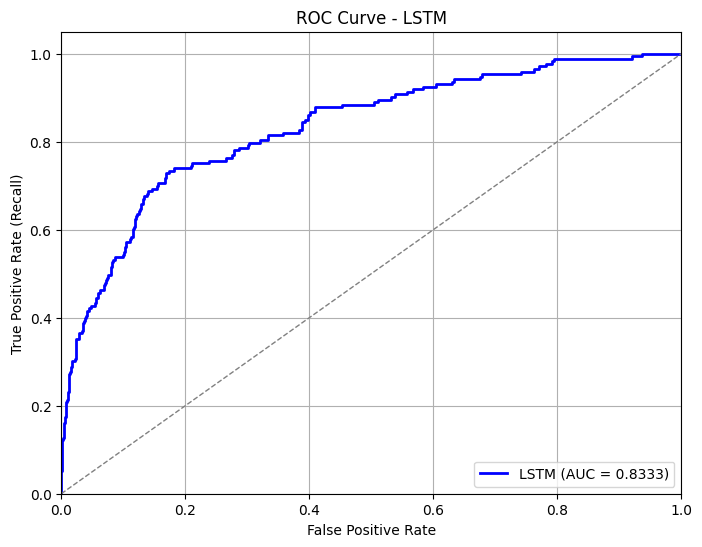

In [34]:
loss, accuracy, precision, recall = model.evaluate(X_test_lstm, y_test_lstm)
print(f"\nTest Accuracy: {accuracy:.4f}")
y_pred_probs = model.predict(X_test_lstm)
y_pred_lstm = (y_pred_probs > 0.5).astype("int32").flatten()
plot_roc_curve(y_test_lstm, y_pred_probs, model_name="LSTM")


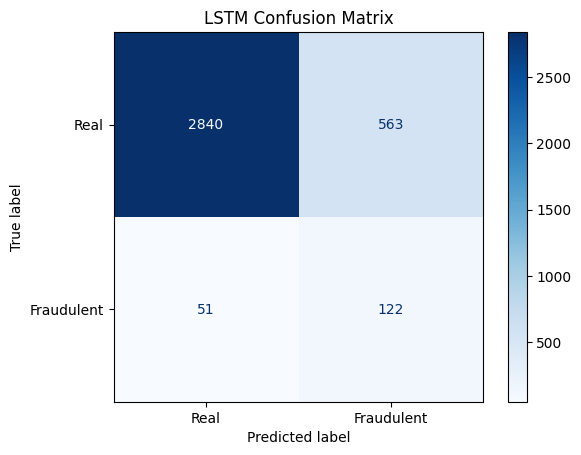

In [35]:
cm = confusion_matrix(y_test_lstm, y_pred_lstm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Real", "Fraudulent"])
disp.plot(cmap=plt.cm.Blues)
plt.title("LSTM Confusion Matrix")
plt.show()

Best Threshold (based on F1): 0.72
Precision: 0.427, Recall: 0.353, F1: 0.386


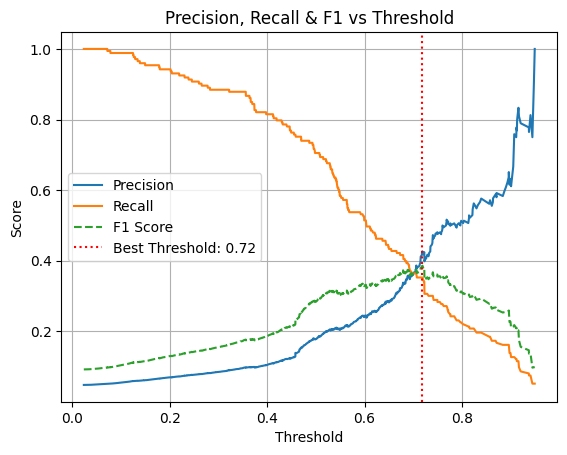

In [36]:
from sklearn.metrics import precision_recall_curve, f1_score
import matplotlib.pyplot as plt
import numpy as np

# Get precision, recall, and thresholds from raw probabilities
precision, recall, thresholds = precision_recall_curve(y_test_lstm, y_pred_probs)

# Compute F1 score for each threshold (ignore final point — it's not a real threshold)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-6)  # avoid division by zero

# Find the threshold with the best F1
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
print(f"Best Threshold (based on F1): {best_threshold:.2f}")
print(f"Precision: {precision[best_idx]:.3f}, Recall: {recall[best_idx]:.3f}, F1: {f1_scores[best_idx]:.3f}")

# Plot precision-recall vs thresholds
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores[:-1], label="F1 Score", linestyle="--")
plt.axvline(x=best_threshold, color='r', linestyle=':', label=f"Best Threshold: {best_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall & F1 vs Threshold")
plt.legend()
plt.grid(True)
plt.show()


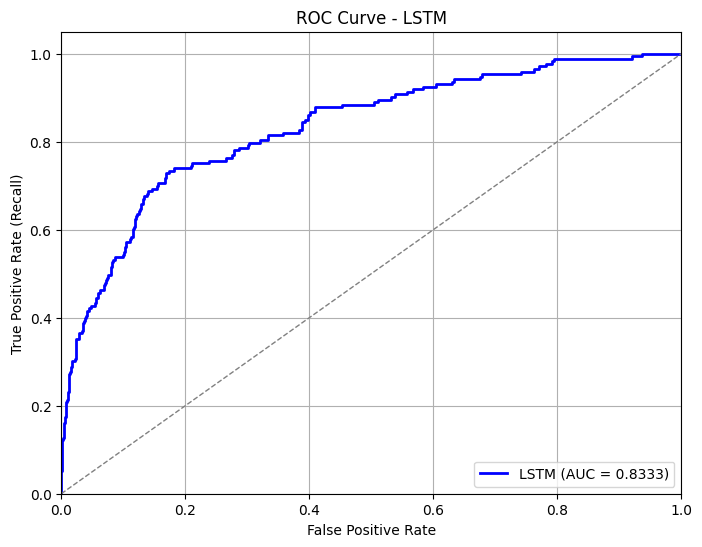

In [37]:
# Apply the selected optimal threshold (0.68)
y_pred_lstm = (y_pred_probs > 0.68).astype("int32").flatten()
plot_roc_curve(y_test_lstm, y_pred_probs, model_name="LSTM")

Classification Report with Tuned Threshold (0.68):
              precision    recall  f1-score   support

        Real       0.97      0.96      0.96      3403
  Fraudulent       0.33      0.40      0.37       173

    accuracy                           0.93      3576
   macro avg       0.65      0.68      0.67      3576
weighted avg       0.94      0.93      0.94      3576



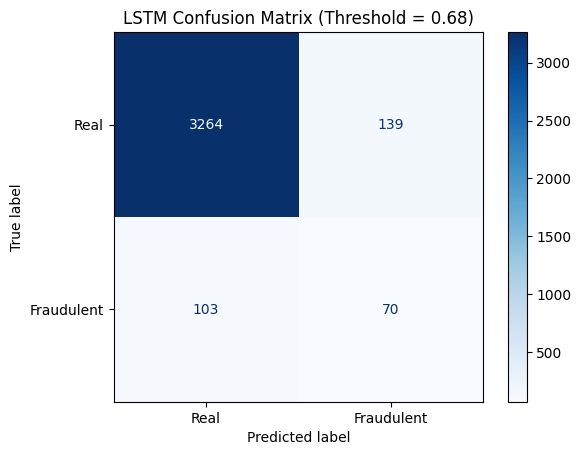

In [38]:
# Evaluate with updated predictions
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Classification Report with Tuned Threshold (0.68):")
print(classification_report(y_test, y_pred_lstm, target_names=["Real", "Fraudulent"]))

cm = confusion_matrix(y_test, y_pred_lstm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Real", "Fraudulent"])
disp.plot(cmap=plt.cm.Blues)
plt.title("LSTM Confusion Matrix (Threshold = 0.68)")
plt.show()


In [39]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test_lstm, y_pred_lstm)

0.9323266219239373

In [40]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Compute threshold-based metrics
lstm_precision = precision_score(y_test_lstm, y_pred_lstm)
lstm_recall = recall_score(y_test_lstm, y_pred_lstm)
lstm_f1 = f1_score(y_test_lstm, y_pred_lstm)
lstm_accuracy = accuracy_score(y_test_lstm, y_pred_lstm)

print(f"Precision: {lstm_precision:.4f}")
print(f"Recall:    {lstm_recall:.4f}")
print(f"F1 Score:  {lstm_f1:.4f}")
print(f"Accuracy:  {lstm_accuracy:.4f}")

Precision: 0.3349
Recall:    0.4046
F1 Score:  0.3665
Accuracy:  0.9323


<p> LSTM accuracy is lower due to a custom threshold (0.68) selected to improve recall and F1 score for the minority (fraudulent) class.

</p>

In [41]:
import pandas as pd
from sklearn.metrics import roc_auc_score

# LSTM ROC-AUC
roc_auc_lstm = roc_auc_score(y_test_lstm, y_pred_probs)

# XGBoost ROC-AUC
roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)

# Logistic Regression ROC-AUC (if you already have y_pred_proba_log)
roc_auc_log = roc_auc_score(y_test, y_pred_proba_log)

# Build table
comparison_data = {
    "Model": ["Logistic Regression", "XGBoost", "LSTM"],
    "Accuracy": [
        log_reg_results["Accuracy"],
        xgb_results["Accuracy"],
        lstm_accuracy
    ],
    "Precision": [
        log_reg_results["Precision"],
        xgb_results["Precision"],
        lstm_precision
    ],
    "Recall": [
        log_reg_results["Recall"],
        xgb_results["Recall"],
        lstm_recall
    ],
    "F1 Score": [
        log_reg_results["F1 Score"],
        xgb_results["F1 Score"],
        lstm_f1
    ],
    "ROC-AUC": [
        roc_auc_log,
        roc_auc_xgb,
        roc_auc_lstm
    ]
}

df_comparison = pd.DataFrame(comparison_data)
df_comparison = df_comparison.round(4)
display(df_comparison)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9511,0.4968,0.8960,0.6392,0.9723
1,XGBoost,0.9782,0.8025,0.7283,0.7636,0.9639
2,LSTM,0.9323,0.3349,0.4046,0.3665,0.8333
